# Demo kiểm định H1–H4

Chạy phép thử và độ nhạy đúng cấu hình. H4a Monte Carlo giữ 99.999 lần mô phỏng; cell đó có thể chờ lâu. Không giảm số mô phỏng rồi gọi là cùng kết quả nghiên cứu.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: C:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
OUT = demo_directory(PATHS, 'hypothesis_tests')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\hypothesis_tests_20261116_035932_8ed44b58


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Đọc và kiểm tra các mẫu
Chuẩn bị đủ 4 mẫu; kiểm tra nhất quán giữa các nguồn.

In [3]:
from source.inference import range_tests, cafv_test, county_tests
from source.inference.run_inference import validate_sample_consistency
ranges = range_tests.load_range(PATHS.preparation/'range_analysis_sample.csv')
cafv = cafv_test.load_cafv(PATHS.preparation/'cafv_analysis_sample.csv')
counties = county_tests.load_counties(PATHS.preparation/'county_vehicle_type_counts.csv')
snapshots = county_tests.load_snapshots(PATHS.preparation/'county_ev_snapshots.csv')
validate_sample_consistency(ranges,cafv,counties,snapshots)
display(pd.DataFrame({'sample':['Range','CAFV','County composition','Snapshots'],
                      'rows':[len(ranges),len(cafv),len(counties),len(snapshots)]}))


,sample,rows
0,Range,77857
1,CAFV,134726
2,County composition,39
3,Snapshots,78


## H1/H2: Range
Mann–Whitney và Spearman; phân biệt p-value với cỡ ảnh hưởng. Đọc H1 không mặc định là kiểm định riêng trung vị.

def run_tests(frame: pd.DataFrame) -> tuple[pd.DataFrame,pd.DataFrame]:
    rows=[]
    for sample,part in [('primary',frame),('year_le_2020',frame.loc[frame['h1_year_le_2020']])]:
        bev=part.loc[part['vehicle_type'].eq('BEV'),'electric_range'].to_numpy()
        phev=part.loc[part['vehicle_type'].eq('PHEV'),'electric_range'].to_numpy()
        require(len(bev)>0 and len(phev)>0,'H1 requires nonempty BEV and PHEV samples.')
        result=stats.mannwhitneyu(bev,phev,alternative='two-sided',method='asymptotic',use_continuity=True,nan_policy='raise')
        superiority=float(result.statistic)/(len(bev)*len(phev))
        row={'hypothesis':'H1','sample':sample,'status':'computed','statistic_name':'Mann-Whitney U (BEV)',
             'statistic':float(result.statistic),'n':len(part),'n_bev':len(bev),'n_phev':len(phev),
             'p_method':'asymptotic normal, ties and continuity corrected','alternative':'two-sided',
             **p_report(float(result.pvalue)),'effect_name':'rank-biserial (BEV minus PHEV)',
             'effect_size':2*superiority-1,'probability_superiority_bev':superiority,
             'effect_definition':'A=P(BEV>PHEV)+0.5*P(tie)=U_BEV/(n_BEV*n_PHEV); rank_biserial=2*A-1.'}
        for name,values in [('bev',bev),('phev',phev)]:
            q1,q3=np.quantile(values,[.25,.75],method='linear')
            row[name+'_median_miles']=float(np.median(values))
            row[name+'_q1_miles']=float(q1)
            row[name+'_q3_miles']=float(q3)
            row[name+'_iqr_miles']=float(q3-q1)
        rows.append(row)
    paired=frame.loc[frame['h2_valid']]
    for sample,part in [('all_valid',paired),('bev',paired.loc[paired['vehicle_type'].eq('BEV')]),('phev',paired.loc[paired['vehicle_type'].eq('PHEV')])]:
        row={'hypothesis':'H2','sample':sample,'n':len(part),'statistic_name':'Spearman rho',
             'p_method':'asymptotic t approximation','alternative':'two-sided','effect_name':'Spearman rho',
             'effect_definition':'Correlation of average ranks of Model Year and Electric Range; no causal interpretation.'}
        if len(part)<3 or part['model_year'].nunique()<2 or part['electric_range'].nunique()<2:
            row.update({'status':'undefined_constant_or_small_sample','statistic':None,'effect_size':None,
                        'p_value':None,'p_display':'not computed','p_numerical_underflow':False,
                        'p_value_upper_bound':None,'nominal_alpha':ALPHA,'reject_h0':None})
        else:
            result=stats.spearmanr(part['model_year'],part['electric_range'],alternative='two-sided',nan_policy='raise')
            row.update({'status':'computed','statistic':float(result.statistic),'effect_size':float(result.statistic),
                        **p_report(float(result.pvalue))})
        rows.append(row)
    year_summary=paired.groupby(['vehicle_type','model_year'])['electric_range'].agg(
        valid_n='size',median_miles='median',q1_miles=lambda s:s.quantile(.25,interpolation='linear'),
        q3_miles=lambda s:s.quantile(.75,interpolation='linear')).reset_index()
    return pd.DataFrame(rows),year_summary

,hypothesis,sample,n,statistic,p_display,effect_name,effect_size
0,H1,primary,77857,1.446940e+09,<1e-300 (numerical underflow),rank-biserial (BEV minus PHEV),0.991147
1,H1,year_le_2020,65779,8.950288e+08,<1e-300 (numerical underflow),rank-biserial (BEV minus PHEV),0.986172
2,H2,all_valid,77857,9.008592e-02,5.5085053e-140,Spearman rho,0.090086
3,H2,bev,46806,7.797733e-01,<1e-300 (numerical underflow),Spearman rho,0.779773
4,H2,phev,31051,3.553657e-02,3.7587837e-10,Spearman rho,0.035537


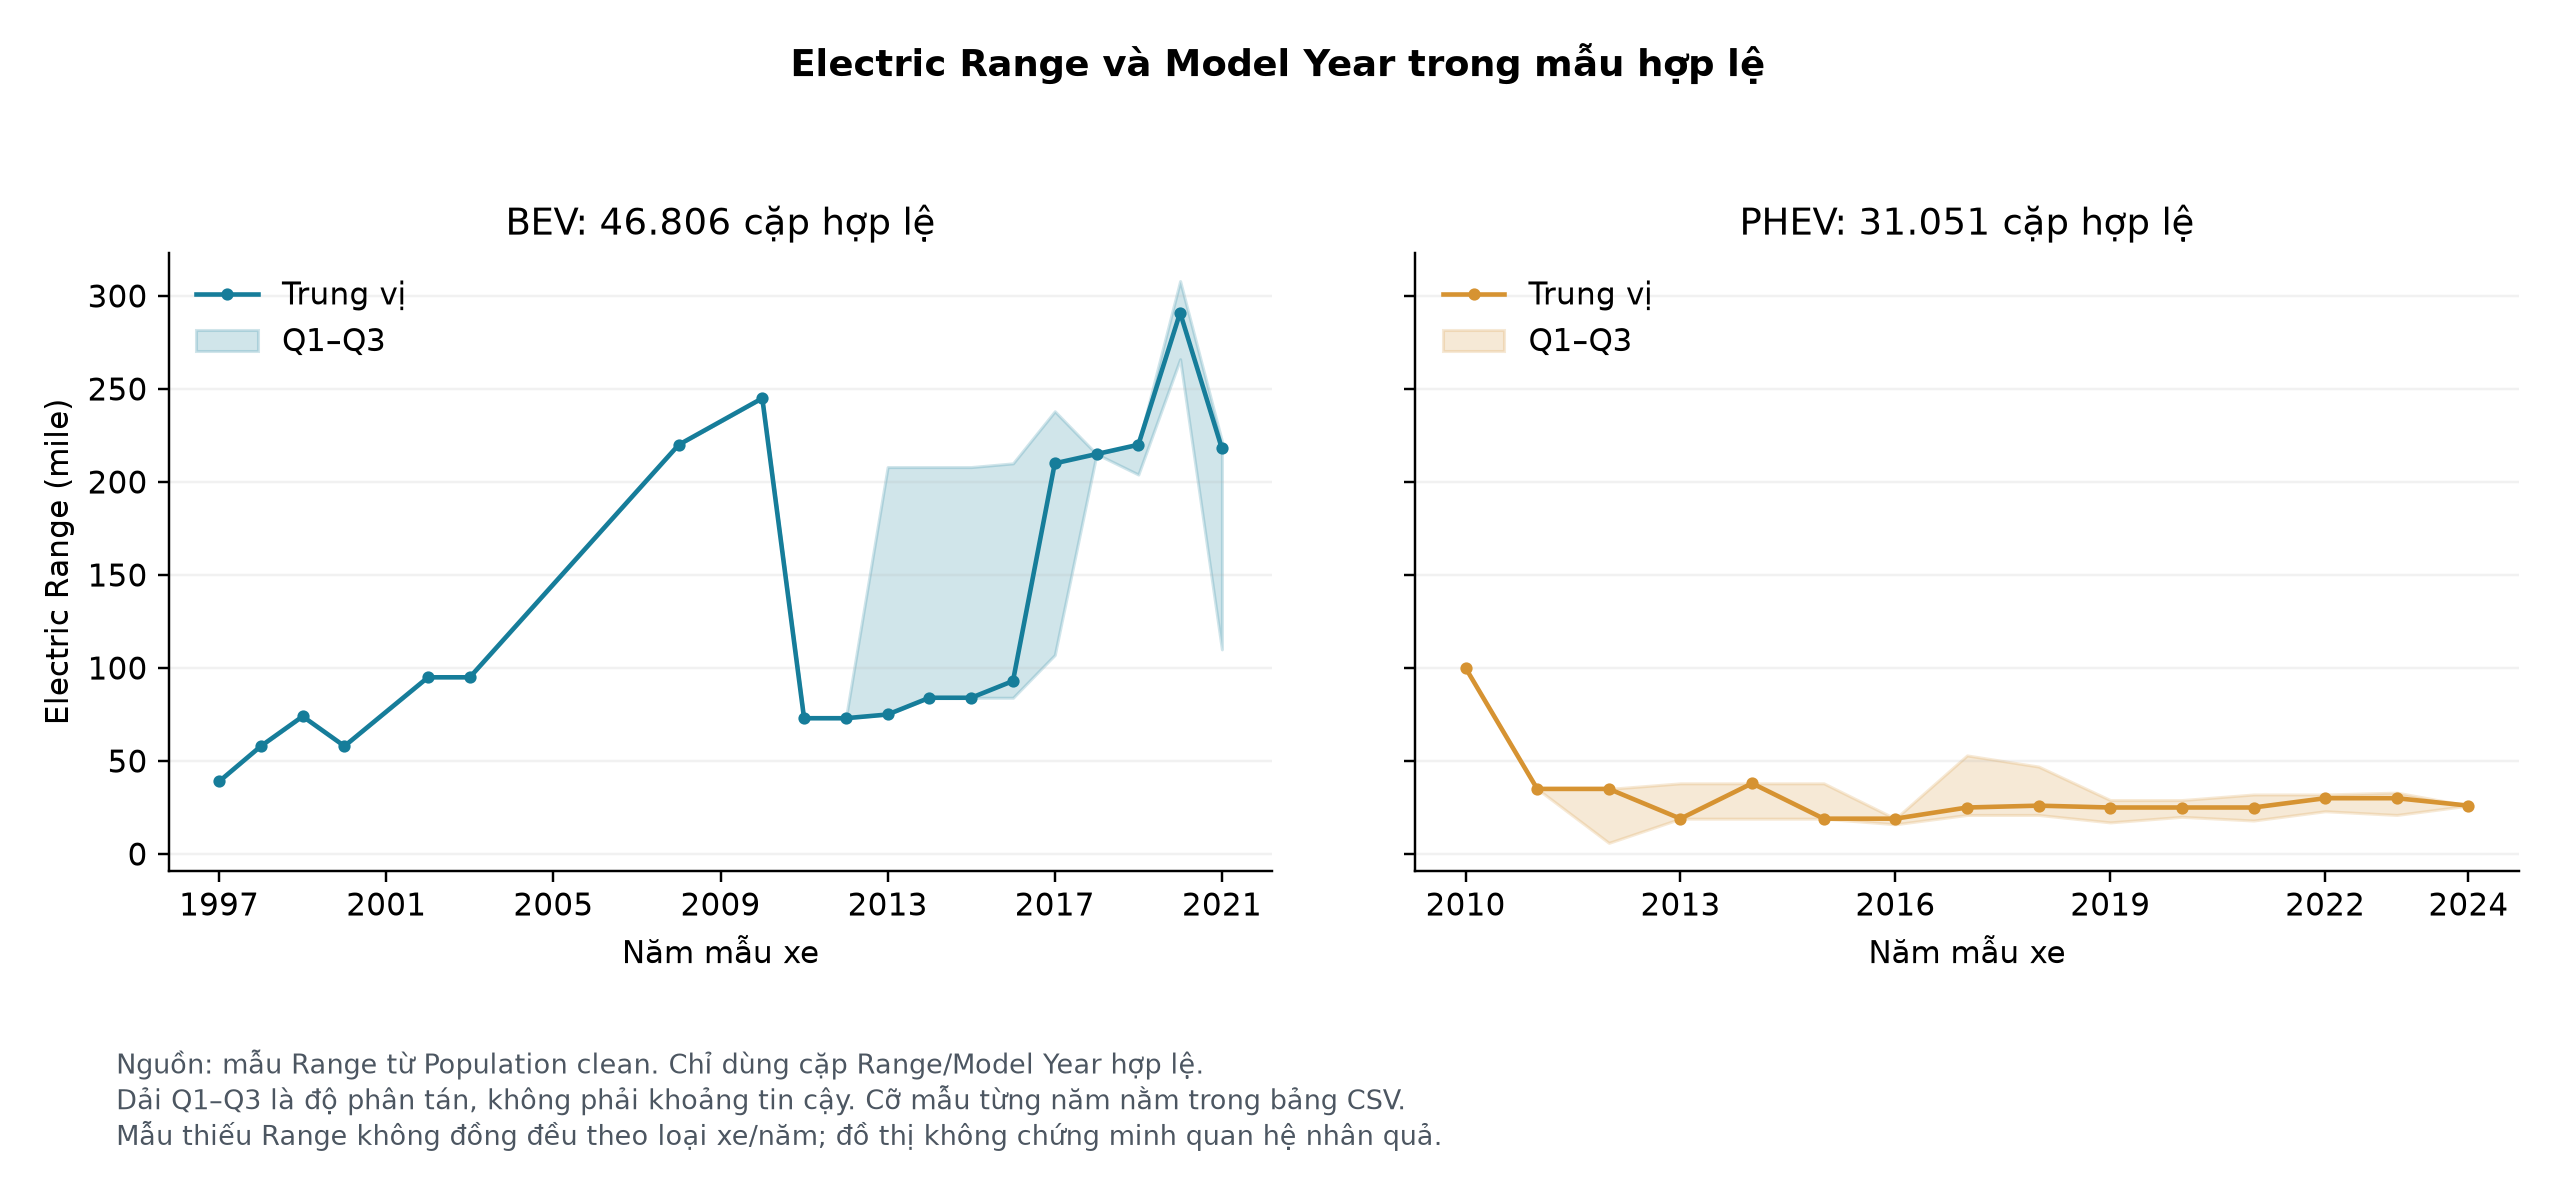

In [4]:
show_source(range_tests.run_tests)
range_results, year_summary = range_tests.run_tests(ranges)
display(range_results[['hypothesis','sample','n','statistic','p_display','effect_name','effect_size']])
(OUT/'figures').mkdir(parents=True, exist_ok=True)
range_tests.export_figure(year_summary, OUT/'figures')
show_png(OUT/'figures/range_by_model_year.png')


## H3: CAFV
Mẫu chính nhãn đã biết, độ nhạy giữ Unknown. Không lọc nhãn CAFV dựa vào Range.

,hypothesis,sample,n,statistic,p_display,effect_size,expected_min
0,H3,known_labels,77858,32165.894934,<1e-300 (numerical underflow),0.642756,6690.350381
1,H3,including_unknown,134726,72957.197086,<1e-300 (numerical underflow),0.735882,3866.345768


,hypothesis,sample,row_label,column_label,observed,expected,expected_lt_5,row_total,column_total,n
0,H3,known_labels,BEV,Clean Alternative Fuel Vehicle Eligible,46796,36721.350381,False,46806,61083,77858
1,H3,known_labels,BEV,Not eligible due to low battery range,10,10084.649619,False,46806,16775,77858
2,H3,known_labels,PHEV,Clean Alternative Fuel Vehicle Eligible,14287,24361.649619,False,31052,61083,77858
3,H3,known_labels,PHEV,Not eligible due to low battery range,16765,6690.350381,False,31052,16775,77858
4,H3,including_unknown,BEV,Clean Alternative Fuel Vehicle Eligible,46796,47004.430785,False,103674,61083,134726
5,H3,including_unknown,BEV,Not eligible due to low battery range,10,12908.654232,False,103674,16775,134726
6,H3,including_unknown,BEV,Eligibility unknown as battery range has not b...,56868,43760.914983,False,103674,56868,134726
7,H3,including_unknown,PHEV,Clean Alternative Fuel Vehicle Eligible,14287,14078.569215,False,31052,61083,134726
8,H3,including_unknown,PHEV,Not eligible due to low battery range,16765,3866.345768,False,31052,16775,134726
9,H3,including_unknown,PHEV,Eligibility unknown as battery range has not b...,0,13107.085017,False,31052,56868,134726


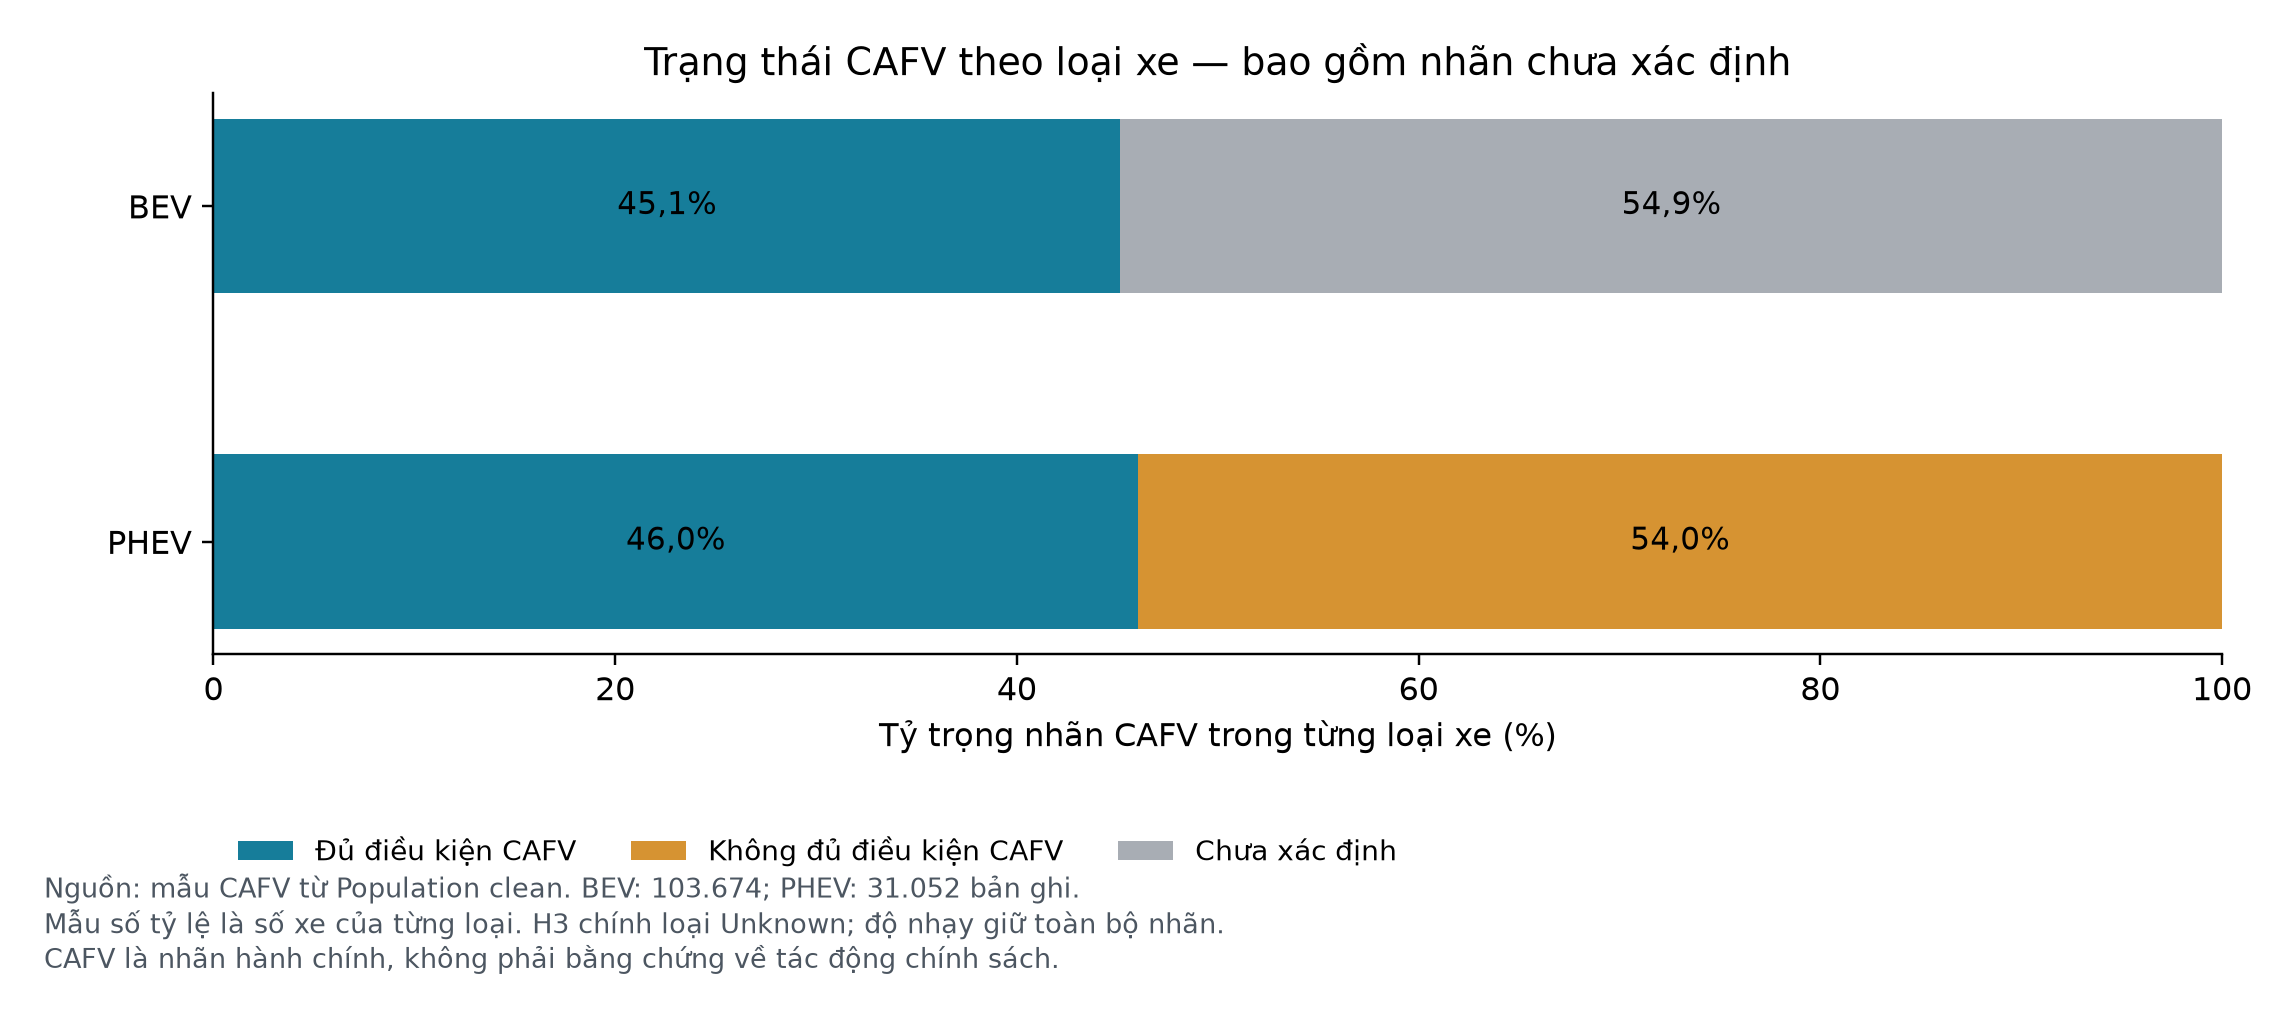

In [5]:
cafv_results, cafv_cells = cafv_test.run_tests(cafv)
display(cafv_results[['hypothesis','sample','n','statistic','p_display','effect_size','expected_min']])
display(cafv_cells.head(10))
cafv_test.export_figure(cafv, OUT/'figures')
show_png(OUT/'figures/cafv_by_vehicle_type.png')


## H4: địa bàn và kiểm tra expected
Cell này thực sự chạy Monte Carlo theo cấu hình mặc định của source: 99.999 lần, seed 42. P chạm độ phân giải không phải cận trên của p thật.

,resamples,seed,batch
0,99999,42,1000


,hypothesis,sample,n,p_method,p_display,effect_size,expected_min
0,H4a,all_counties,134726,"Monte Carlo, fixed margins",1e-05 (Monte Carlo resolution limit),0.109774,0.691448
1,H4a,county_ev_ge_30,134683,asymptotic chi-square,<1e-300 (numerical underflow),0.109579,7.376135
2,H4b,latest_month,5954054,asymptotic chi-square,<1e-300 (numerical underflow),0.110169,59.355063
3,H4b,first_month,5940783,asymptotic chi-square,<1e-300 (numerical underflow),0.044546,8.162876


,hypothesis,sample,row_label,column_label,observed,expected,expected_lt_5,row_total,column_total,n,date
0,H4a,all_counties,Adams,bev,27,30.011178,False,39,103674,134726,NaN
1,H4a,all_counties,Adams,phev,12,8.988822,False,39,31052,134726,NaN
2,H4a,all_counties,Asotin,bev,35,42.323456,False,55,103674,134726,NaN
3,H4a,all_counties,Asotin,phev,20,12.676544,False,55,31052,134726,NaN
4,H4a,all_counties,Benton,bev,1135,1298.175838,False,1687,103674,134726,NaN


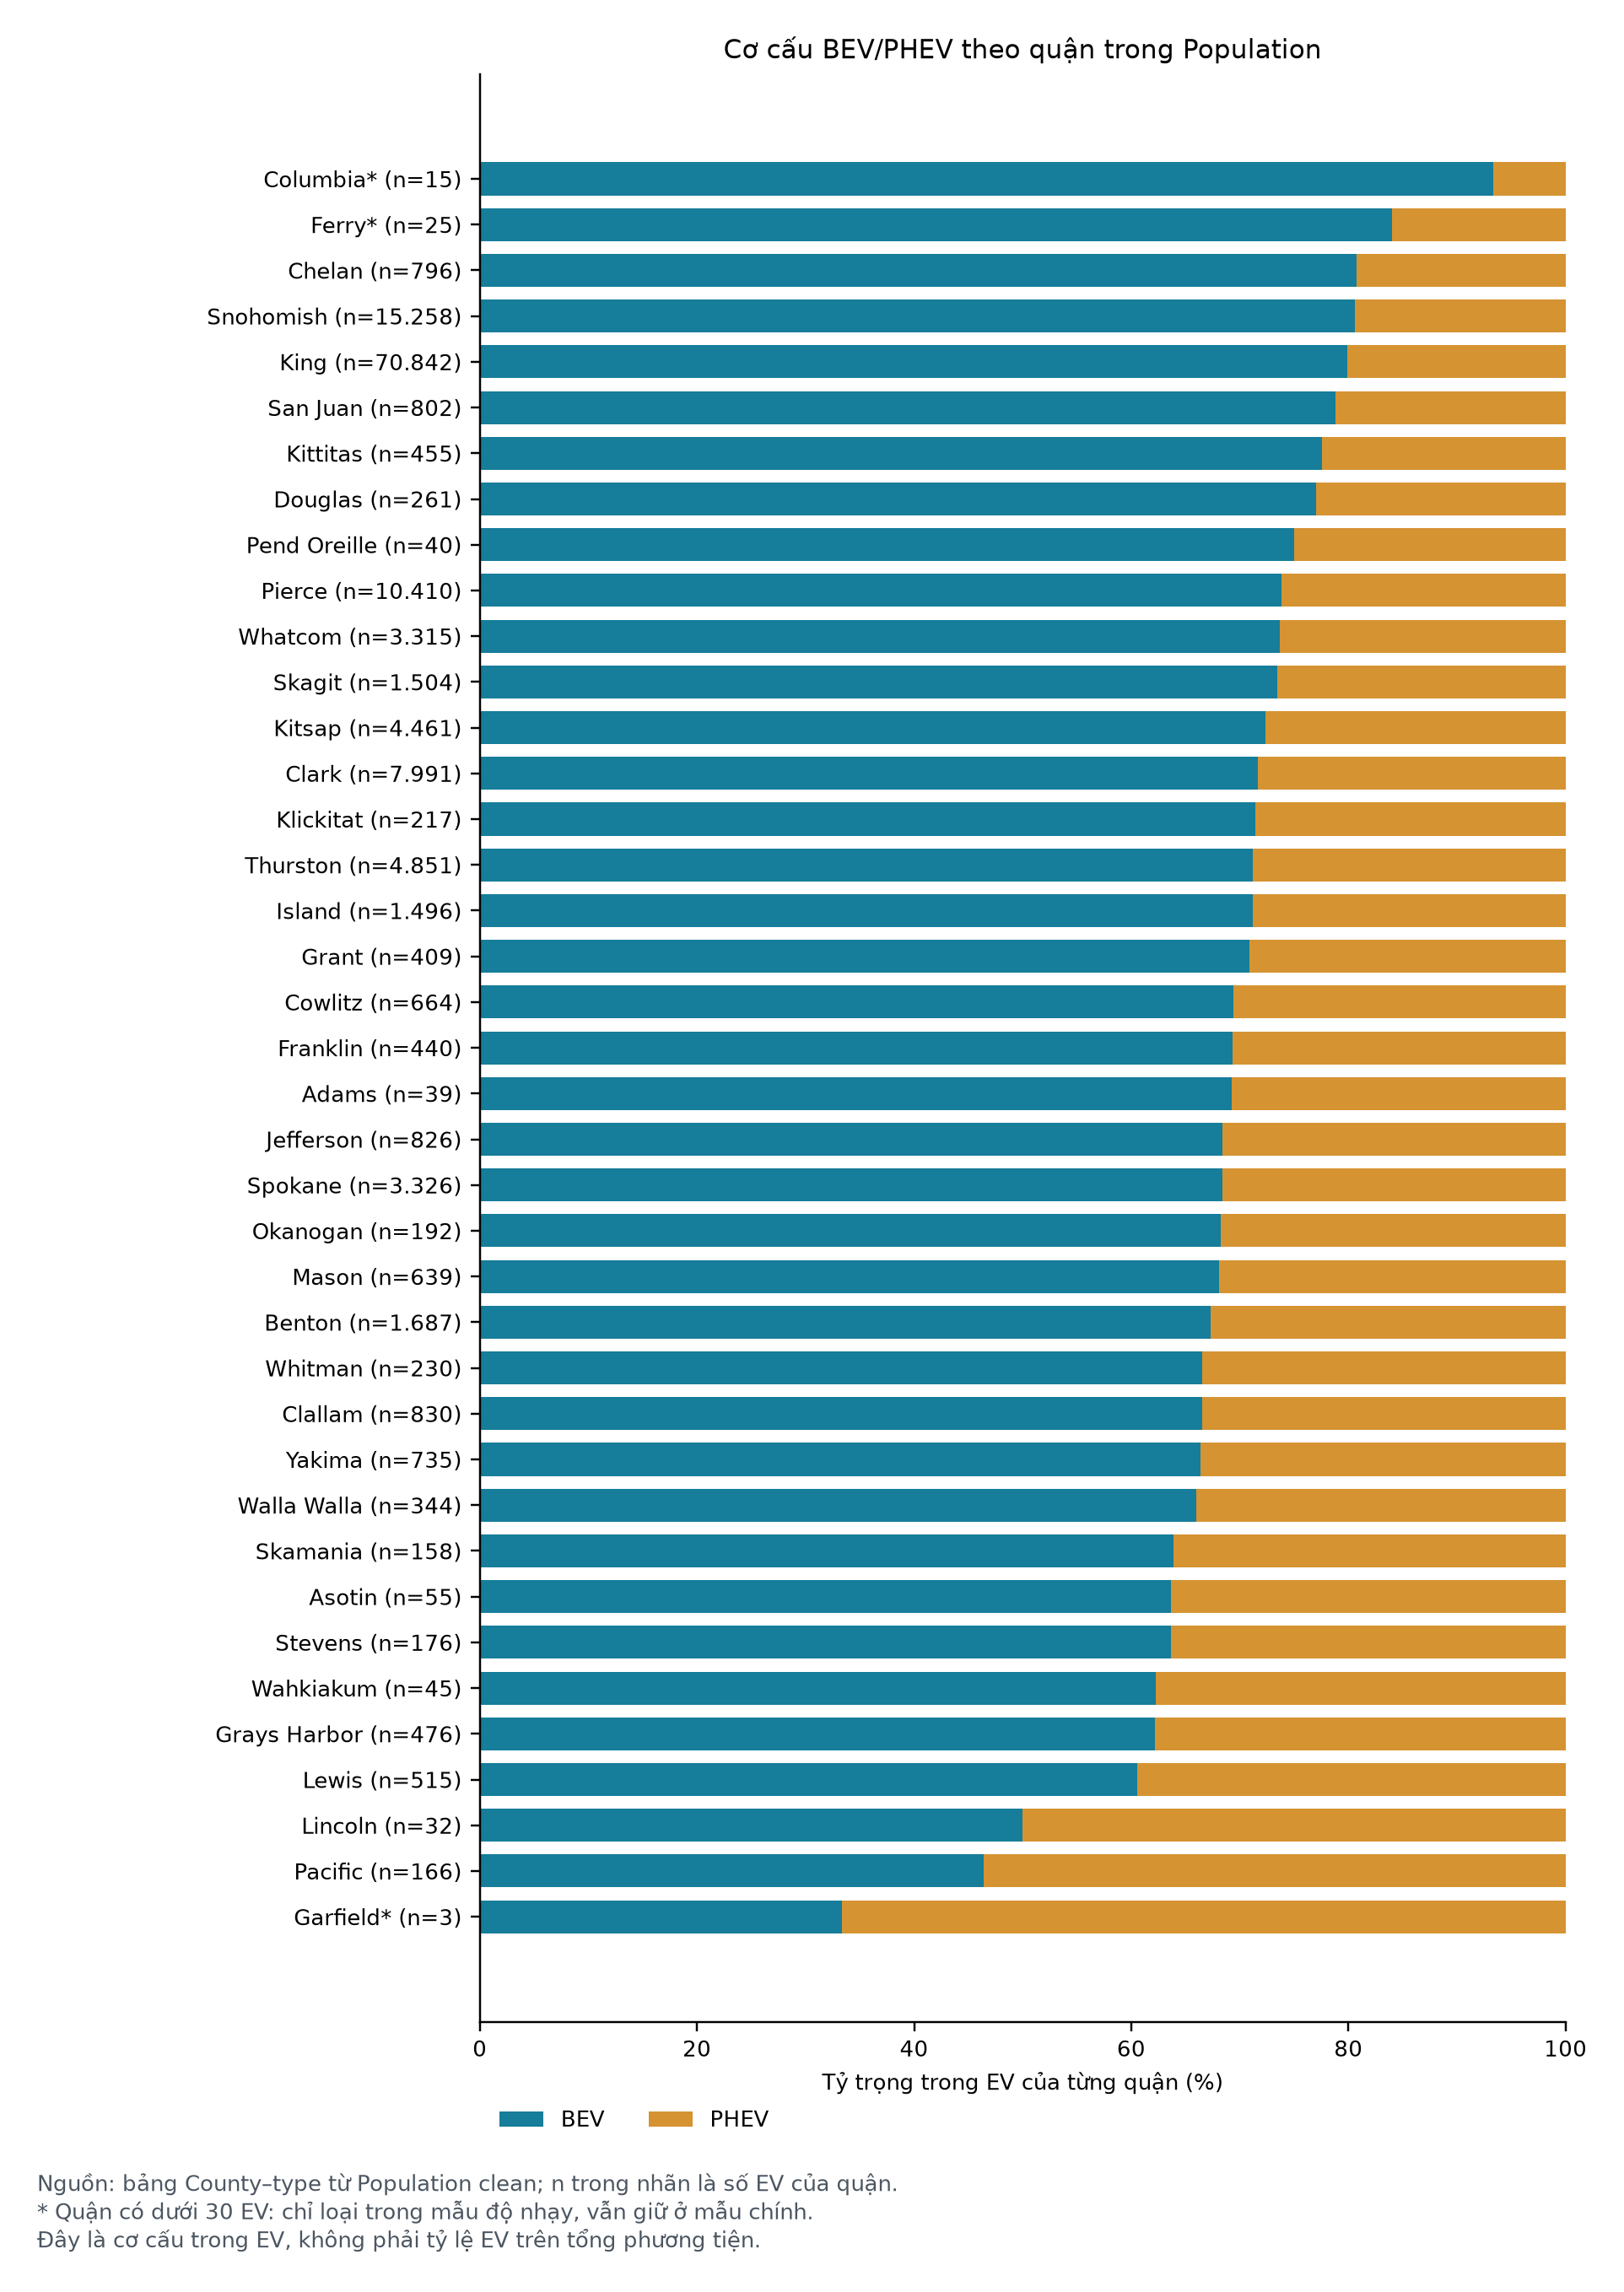

In [6]:
from source.inference.contingency import N_RESAMPLES, SEED, BATCH
display(pd.DataFrame([{'resamples':N_RESAMPLES,'seed':SEED,'batch':BATCH}]))
county_results, county_cells = county_tests.run_tests(counties, snapshots)
display(county_results[['hypothesis','sample','n','p_method','p_display','effect_size','expected_min']])
display(county_cells.head())
county_tests.export_figure(counties, OUT/'figures')
show_png(OUT/'figures/county_vehicle_type_share.png')


## Tổng hợp và đối chiếu
11 dòng bao gồm chính/độ nhạy/phân nhóm. P dưới giới hạn số học không được gọi là p=0; các p chưa điều chỉnh đa kiểm định.

In [7]:
reference = pd.read_csv(PROJECT_ROOT/'results/inference/hypothesis_summary.csv')
summary = pd.concat([range_results,cafv_results,county_results],ignore_index=True).reindex(columns=reference.columns)
from io import StringIO
# So nội dung CSV: None/NaN đều được xuất thành ô trống, không phải p=0.
csv_view = pd.read_csv(StringIO(summary.to_csv(index=False)))
pd.testing.assert_frame_equal(csv_view, reference, check_dtype=False, rtol=1e-7, atol=1e-10)
display(summary[['hypothesis','sample','p_display','effect_name','effect_size','reject_h0']])
for name,frame in {'range_tests.csv':range_results,'range_year_summary.csv':year_summary,
                   'cafv_tests.csv':cafv_results,'cafv_contingency.csv':cafv_cells,
                   'county_tests.csv':county_results,'county_contingency.csv':county_cells,
                   'hypothesis_summary.csv':summary}.items(): save_table(frame, OUT/name)
print('Kiểm định và bảng tổng hợp khớp kết quả đã lưu.')


,hypothesis,sample,p_display,effect_name,effect_size,reject_h0
0,H1,primary,<1e-300 (numerical underflow),rank-biserial (BEV minus PHEV),0.991147,True
1,H1,year_le_2020,<1e-300 (numerical underflow),rank-biserial (BEV minus PHEV),0.986172,True
2,H2,all_valid,5.5085053e-140,Spearman rho,0.090086,True
3,H2,bev,<1e-300 (numerical underflow),Spearman rho,0.779773,True
4,H2,phev,3.7587837e-10,Spearman rho,0.035537,True
5,H3,known_labels,<1e-300 (numerical underflow),Cramers V,0.642756,True
6,H3,including_unknown,<1e-300 (numerical underflow),Cramers V,0.735882,True
7,H4a,all_counties,1e-05 (Monte Carlo resolution limit),Cramers V,0.109774,True
8,H4a,county_ev_ge_30,<1e-300 (numerical underflow),Cramers V,0.109579,True
9,H4b,latest_month,<1e-300 (numerical underflow),Cramers V,0.110169,True


Kiểm định và bảng tổng hợp khớp kết quả đã lưu.
